# 8. Interpretación del modelo con SHAP

La importancia por permutación (cuadernos 4 y 5) dice **qué tanto** importa cada variable, pero no **en qué dirección** ni **para quién**. **SHAP** (*SHapley Additive exPlanations*) responde las tres preguntas:

| Pregunta | Herramienta SHAP |
|---|---|
| ¿Qué variables importan más en general? | Importancia global (barras) |
| ¿Valores altos de una variable suben o bajan la probabilidad de sobrevivir? | Gráfica *beeswarm* |
| ¿Cómo cambia el efecto según el valor de la variable? ¿Hay interacciones? | Gráficas de dependencia |
| ¿Por qué el modelo predijo esto para **este** pasajero? | Gráfica *waterfall* |

**Idea clave:** SHAP reparte la predicción de cada pasajero entre sus variables, como se reparten las ganancias de un equipo según lo que aportó cada jugador (valores de Shapley, teoría de juegos):

`predicción del pasajero = valor base (promedio) + suma de las contribuciones SHAP de sus variables`

Para Gradient Boosting, SHAP trabaja en **log-odds** (escala logarítmica de la razón de momios): valores positivos empujan hacia *sobrevive*, negativos hacia *no sobrevive*.

> Requiere: `pip install shap`

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.base import clone
from sklearn.model_selection import train_test_split

import titanic_features
from titanic_features import NUM_FEATURES, CAT_FEATURES

sns.set_theme(style="whitegrid")
SEED = 42
print("SHAP", shap.__version__)

SHAP 0.53.0


## 8.1 Modelo final (pipeline del cuaderno 5) entrenado con la partición 80/20

In [2]:
raw = pd.read_csv("data/titanic.csv")
X = raw.drop(columns="Survived")
y = raw["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

pipe = clone(joblib.load("models/titanic_pipeline.joblib")).fit(X_train, y_train)
UMBRAL = float(open("results/umbral.txt").read())
print(pipe.named_steps["model"])
print("Umbral de decisión:", UMBRAL)

GradientBoostingClassifier(learning_rate=0.03, max_depth=4, n_estimators=200,
                           random_state=42)
Umbral de decisión: 0.32


## 8.2 Preparar los datos para SHAP
El modelo recibe variables **escaladas** y **one-hot**. Para explicar usamos esa matriz, pero para **mostrar** usamos los valores originales (edad en años, tarifa en libras) para que las gráficas se entiendan.

In [3]:
feat = pipe.named_steps["features"]
prep = pipe.named_steps["prep"]
gb = pipe.named_steps["model"]

nombres = [n.replace("num__", "").replace("cat__", "") for n in prep.get_feature_names_out()]

def matrices(Xraw):
    f = feat.transform(Xraw)
    Xm = pd.DataFrame(prep.transform(f), columns=nombres, index=Xraw.index)      # lo que ve el modelo
    Xv = Xm.copy()
    Xv[NUM_FEATURES] = f[NUM_FEATURES].values                                      # valores legibles
    return Xm, Xv

Xm_test, Xv_test = matrices(X_test)
print(Xm_test.shape, "variables que ve el modelo")
Xv_test.head(3)

(179, 33) variables que ve el modelo


,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin,FarePerPerson,IsChild,...,Deck_D,Deck_E,Deck_F,Deck_G,Deck_U,AgeGroup_Adolescente,AgeGroup_Adulto,AgeGroup_Joven,AgeGroup_Mayor,AgeGroup_Niño
565,3.0,24.0,2.0,0.0,24.150,3.0,0.0,0.0,8.050,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
160,3.0,44.0,0.0,1.0,16.100,2.0,0.0,0.0,8.050,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
553,3.0,22.0,0.0,0.0,7.225,1.0,1.0,0.0,7.225,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [4]:
explainer = shap.TreeExplainer(gb)
sv = explainer(Xm_test)
sv = shap.Explanation(values=sv.values, base_values=sv.base_values, data=Xv_test.values, feature_names=nombres)

base = float(np.atleast_1d(explainer.expected_value)[0])
prob_base = 1 / (1 + np.exp(-base))
print(f"Valor base: {base:.3f} log-odds = {prob_base:.1%} de probabilidad de sobrevivir (promedio del entrenamiento)")

# Comprobación de aditividad: base + suma de SHAP = predicción del modelo
pred_logodds = gb.decision_function(Xm_test)
print("Error máximo de aditividad:", np.abs(base + sv.values.sum(1) - pred_logodds).max().round(8))

Valor base: -0.645 log-odds = 34.4% de probabilidad de sobrevivir (promedio del entrenamiento)
Error máximo de aditividad: 0.0


## 8.3 Importancia global
Promedio del valor **absoluto** SHAP: cuánto mueve cada variable la predicción, en promedio.

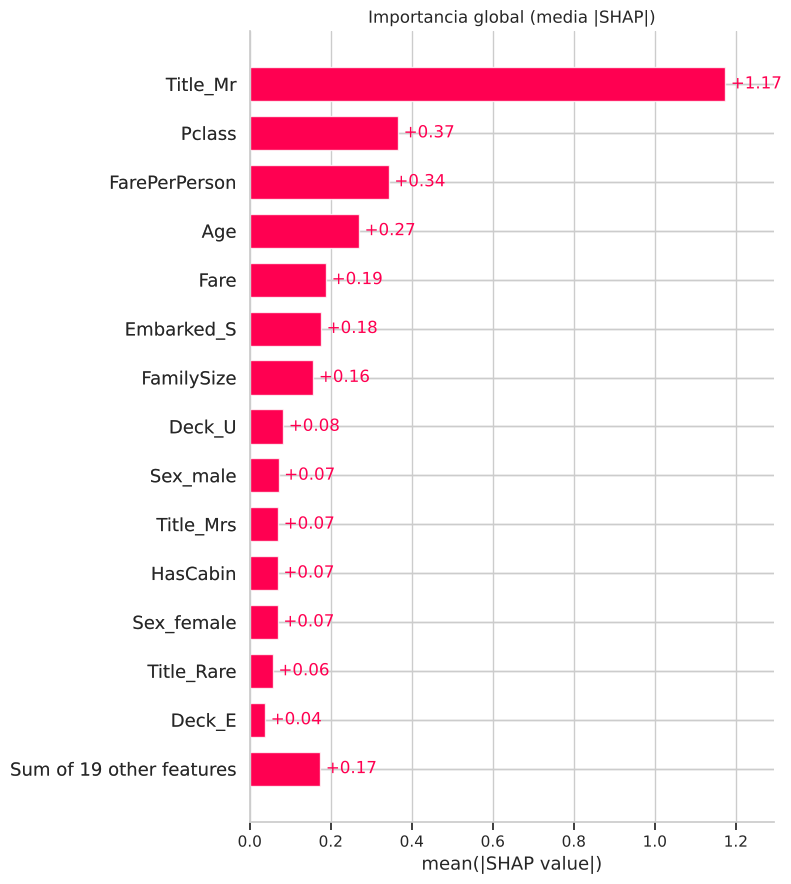

In [5]:
shap.plots.bar(sv, max_display=15, show=False)
plt.title("Importancia global (media |SHAP|)")
plt.tight_layout(); plt.show()

Las variables one-hot dividen una misma característica en varias columnas (ej. `Title_Mr`, `Title_Mrs`…). Sumándolas obtenemos la importancia por **característica original**:

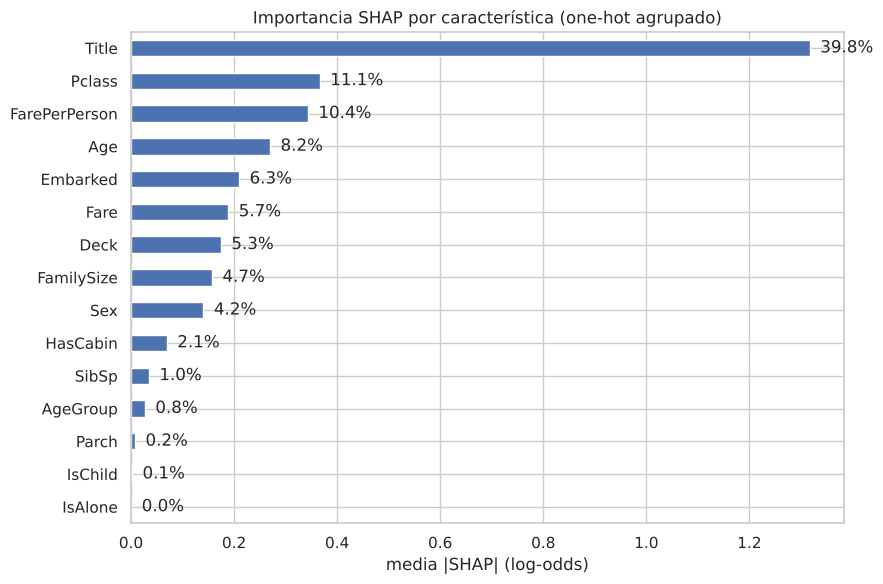

,% de la importancia total
Title,39.8
Pclass,11.1
FarePerPerson,10.4
Age,8.2
Embarked,6.3
Fare,5.7
Deck,5.3
FamilySize,4.7
Sex,4.2
HasCabin,2.1


In [6]:
def grupo(n):
    for c in CAT_FEATURES:
        if n.startswith(c + "_"):
            return c
    return n

imp = pd.Series(np.abs(sv.values).mean(0), index=nombres)
imp_grupo = imp.groupby(imp.index.map(grupo)).sum().sort_values(ascending=False)
imp_grupo_pct = (imp_grupo / imp_grupo.sum() * 100).round(1)

ax = imp_grupo.sort_values().plot.barh(figsize=(9, 6), color="#4c72b0")
for i, (v, p) in enumerate(zip(imp_grupo.sort_values(), imp_grupo_pct[imp_grupo.sort_values().index])):
    ax.text(v, i, f"  {p}%", va="center")
plt.title("Importancia SHAP por característica (one-hot agrupado)")
plt.xlabel("media |SHAP| (log-odds)")
plt.tight_layout(); plt.show()
imp_grupo_pct.to_frame("% de la importancia total")

## 8.4 Dirección del efecto (*beeswarm*)
Cada punto es un pasajero. Posición horizontal = cuánto empujó esa variable su predicción. Color = valor de la variable (rojo alto, azul bajo).

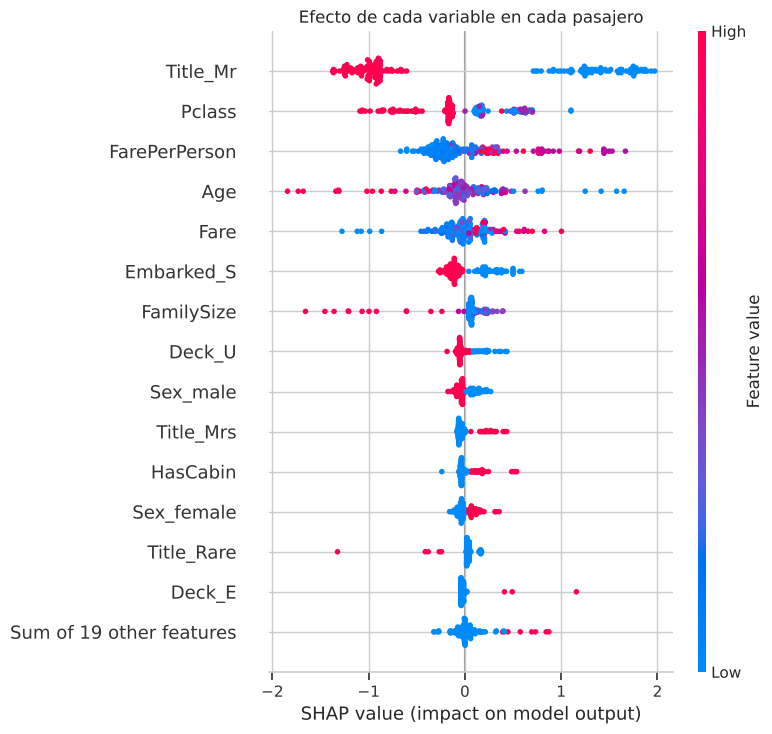

In [7]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("Efecto de cada variable en cada pasajero")
plt.tight_layout(); plt.show()

**Cómo leerlo** (ejemplos):
- `Title_Mr` rojo (= 1, es "Mr") → muy a la izquierda: ser hombre adulto **baja fuertemente** la probabilidad.
- `Pclass` rojo (= 3) → a la izquierda: tercera clase **baja** la probabilidad; azul (primera) la sube.
- `Sex_female` rojo → a la derecha: ser mujer la **sube**.

## 8.5 Gráficas de dependencia: ¿cómo cambia el efecto?

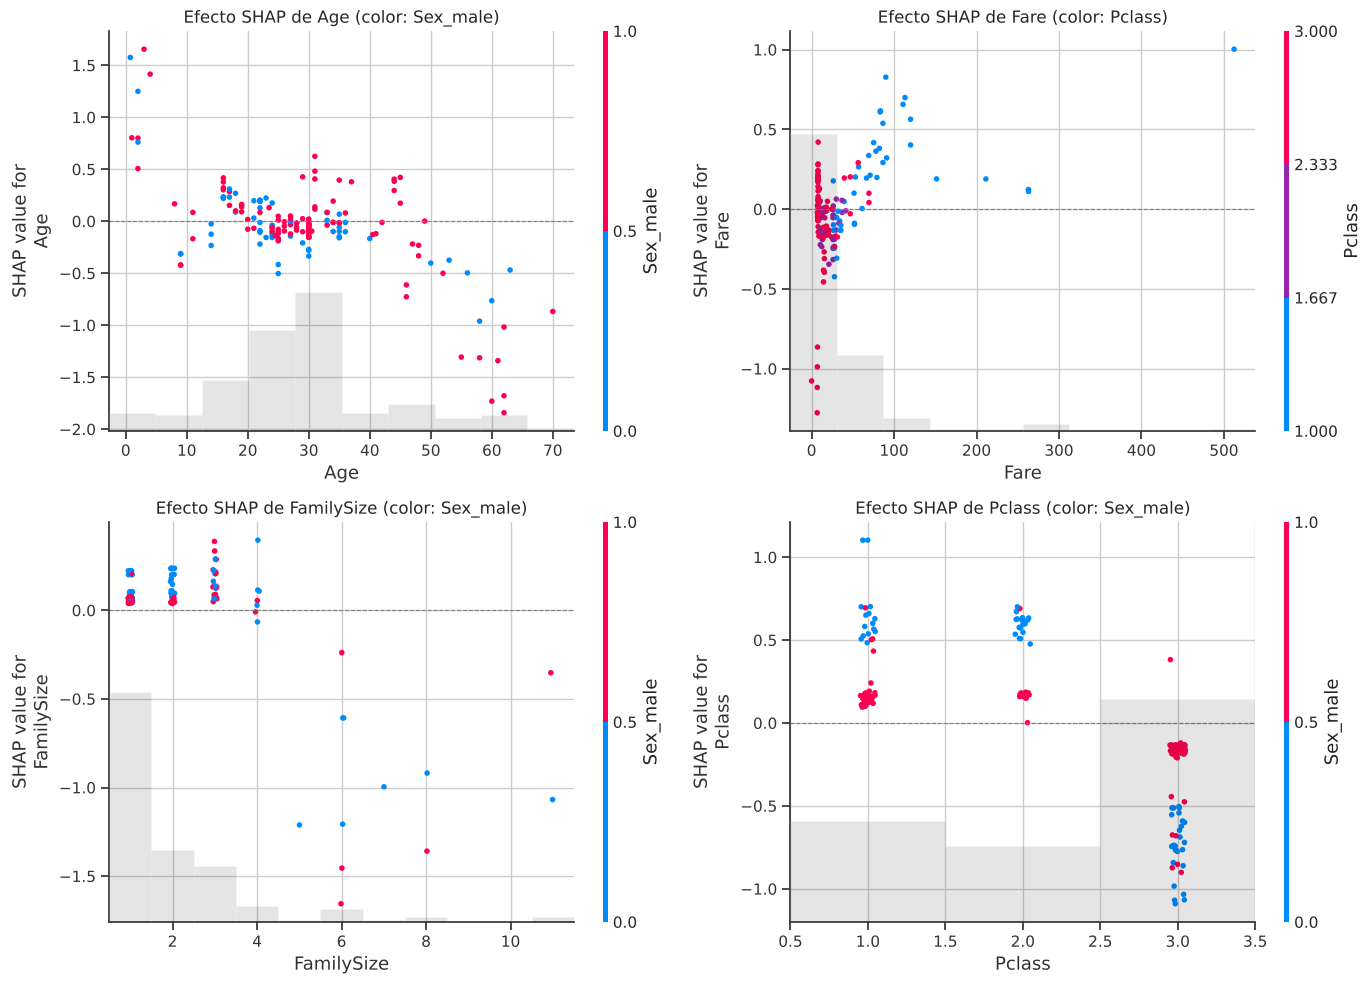

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (var, color) in zip(axes.ravel(), [("Age", "Sex_male"), ("Fare", "Pclass"),
                                           ("FamilySize", "Sex_male"), ("Pclass", "Sex_male")]):
    shap.plots.scatter(sv[:, var], color=sv[:, color], ax=ax, show=False)
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    ax.set_title(f"Efecto SHAP de {var} (color: {color})")
plt.tight_layout(); plt.show()

**Qué se busca en estas gráficas:**
- **Edad:** si los niños (edad baja) tienen SHAP positivo, el modelo aprendió "niños primero".
- **Tarifa:** si el efecto crece con la tarifa y luego se aplana (rendimientos decrecientes).
- **Tamaño de familia:** si la relación es no lineal (solos y familias grandes con SHAP negativo).
- **Clase × sexo:** si los colores se separan verticalmente, hay **interacción**: el efecto de la clase depende del sexo.

Los valores numéricos se cuantifican abajo.

In [9]:
df_s = pd.DataFrame(sv.values, columns=nombres, index=X_test.index)
df_v = Xv_test.copy()

edad = pd.cut(df_v["Age"], [-1, 12, 18, 35, 60, 120], labels=["0-12", "13-18", "19-35", "36-60", "60+"])
print("SHAP medio de Age por grupo de edad:")
print(df_s["Age"].groupby(edad, observed=True).mean().round(3).to_string())

fam = df_v["FamilySize"].clip(upper=5).map({1: "1 (solo)", 2: "2", 3: "3", 4: "4", 5: "5+"})
print("\nSHAP medio de FamilySize:")
print(df_s["FamilySize"].groupby(fam).mean().round(3).to_string())

sexo = np.where(df_v["Sex_male"] == 1, "hombre", "mujer")
print("\nSHAP medio de Pclass por clase y sexo:")
print(df_s["Pclass"].groupby([df_v["Pclass"].astype(int), sexo]).mean().unstack().round(3).to_string())

SHAP medio de Age por grupo de edad:
Age
0-12     0.492
13-18    0.185
19-35   -0.021
36-60   -0.299
60+     -1.203

SHAP medio de FamilySize:
FamilySize
1 (solo)    0.078
2           0.105
3           0.167
4           0.089
5+         -0.973

SHAP medio de Pclass por clase y sexo:
        hombre  mujer
Pclass               
1        0.198  0.660
2        0.191  0.593
3       -0.204 -0.732


## 8.6 Interacciones
SHAP puede separar el efecto **individual** de cada variable del efecto **conjunto** de pares de variables.

In [10]:
inter = explainer.shap_interaction_values(Xm_test)
m = np.abs(inter).mean(0).copy()
np.fill_diagonal(m, 0)
fuerza = pd.DataFrame(m, index=nombres, columns=nombres)
pares = fuerza.where(np.triu(np.ones(fuerza.shape), 1).astype(bool)).stack().sort_values(ascending=False)
top = pares.head(10).rename("fuerza de interacción").to_frame()
top.index = [f"{a} × {b}" for a, b in top.index]
top.round(4)

,fuerza de interacción
Pclass × Title_Mr,0.2022
FarePerPerson × Title_Mr,0.0908
FamilySize × Title_Mr,0.0683
Fare × Title_Mr,0.0569
Age × FarePerPerson,0.0518
Pclass × FamilySize,0.0481
Age × Fare,0.0472
Age × Title_Mr,0.0468
Fare × FarePerPerson,0.0457
Age × Embarked_S,0.0419


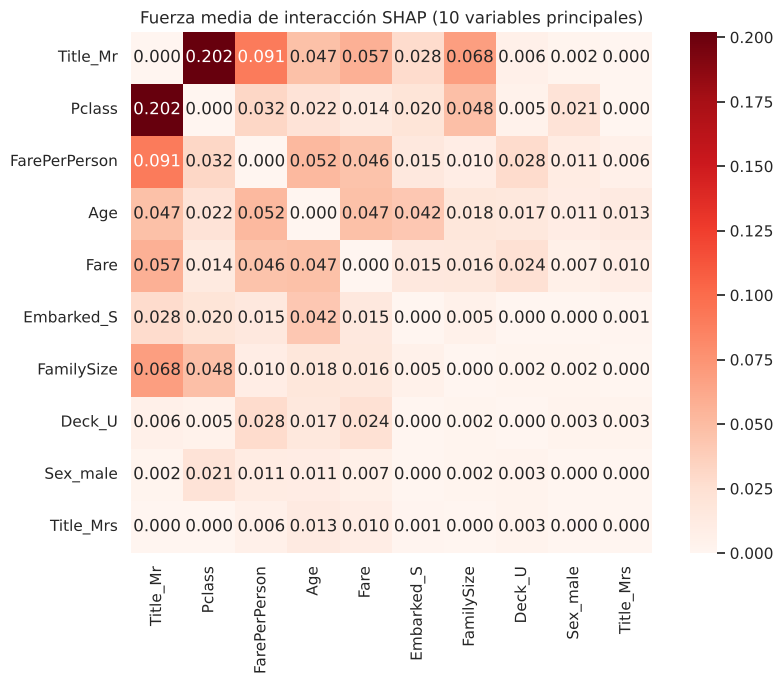

In [11]:
vars_top = list(imp.sort_values(ascending=False).head(10).index)
plt.figure(figsize=(9, 7))
sns.heatmap(fuerza.loc[vars_top, vars_top], cmap="Reds", annot=True, fmt=".3f", square=True)
plt.title("Fuerza media de interacción SHAP (10 variables principales)")
plt.tight_layout(); plt.show()

## 8.7 Explicaciones individuales: ¿por qué el modelo decidió esto?
Elegimos 5 pasajeros de prueba: dos aciertos claros, uno dudoso cerca del umbral y los dos errores en los que el modelo estaba **más seguro**.

In [12]:
proba = pipe.predict_proba(X_test)[:, 1]
pred = (proba >= UMBRAL).astype(int)
info = X_test[["Name", "Sex", "Age", "Pclass", "Fare", "SibSp", "Parch"]].copy()
info["Prob"] = proba.round(3); info["Pred"] = pred; info["Real"] = y_test.values

real = y_test.values
idx = np.arange(len(proba))
pos = {
    "Acierto: sobrevivió (más seguro)": int(idx[real == 1][np.argmax(proba[real == 1])]),
    "Acierto: no sobrevivió (más seguro)": int(idx[real == 0][np.argmin(proba[real == 0])]),
    "Dudoso (cerca del umbral)": int(np.argmin(np.abs(proba - UMBRAL))),
    "Error: falso positivo más confiado": int(idx[(pred == 1) & (real == 0)][np.argmax(proba[(pred == 1) & (real == 0)])]),
    "Error: falso negativo más confiado": int(idx[(pred == 0) & (real == 1)][np.argmin(proba[(pred == 0) & (real == 1)])]),
}
casos = info.iloc[list(pos.values())].assign(Caso=list(pos.keys())).set_index("Caso")
casos

,Name,Sex,Age,Pclass,Fare,SibSp,Parch,Prob,Pred,Real
Caso,,,,,,,,,,
Acierto: sobrevivió (más seguro),"Aubart, Mme. Leontine Pauline",female,24.0,1,69.3000,0,0,0.979,1,1
Acierto: no sobrevivió (más seguro),"Hart, Mr. Henry",male,NaN,3,6.8583,0,0,0.031,0,0
Dudoso (cerca del umbral),"Newell, Mr. Arthur Webster",male,58.0,1,113.2750,0,2,0.314,0,0
Error: falso positivo más confiado,"Minahan, Dr. William Edward",male,44.0,1,90.0000,2,0,0.990,1,0
Error: falso negativo más confiado,"Tornquist, Mr. William Henry",male,25.0,3,0.0000,0,0,0.030,0,1


Acierto: sobrevivió (más seguro): Aubart, Mme. Leontine Pauline | female, 24.0 años, clase 1 | prob = 97.9% | real: sobrevivió
   principales contribuciones: Title_Mr +1.79, Pclass +0.58, Embarked_S +0.40, Fare +0.34


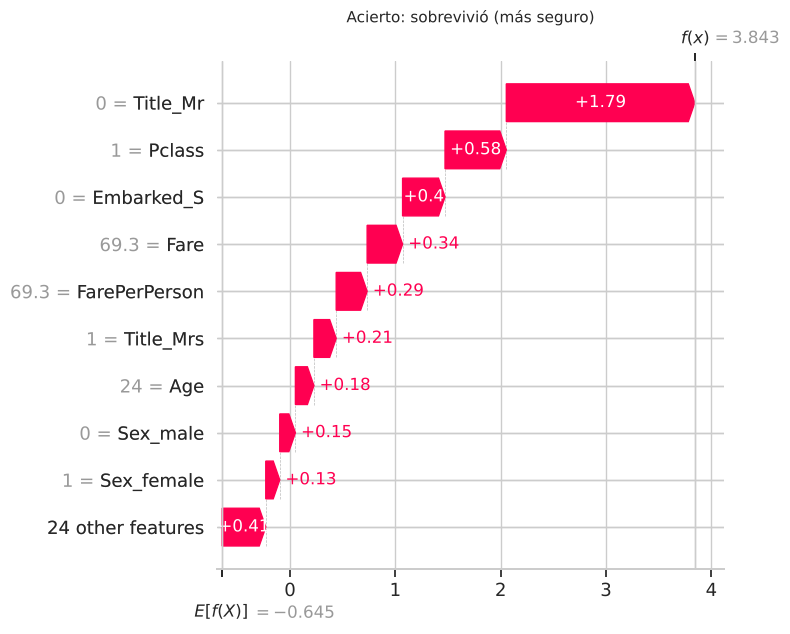

Acierto: no sobrevivió (más seguro): Hart, Mr. Henry | male, edad desconocida años, clase 3 | prob = 3.1% | real: no sobrevivió
   principales contribuciones: Fare -1.12, Title_Mr -0.98, FarePerPerson -0.48, Pclass -0.15


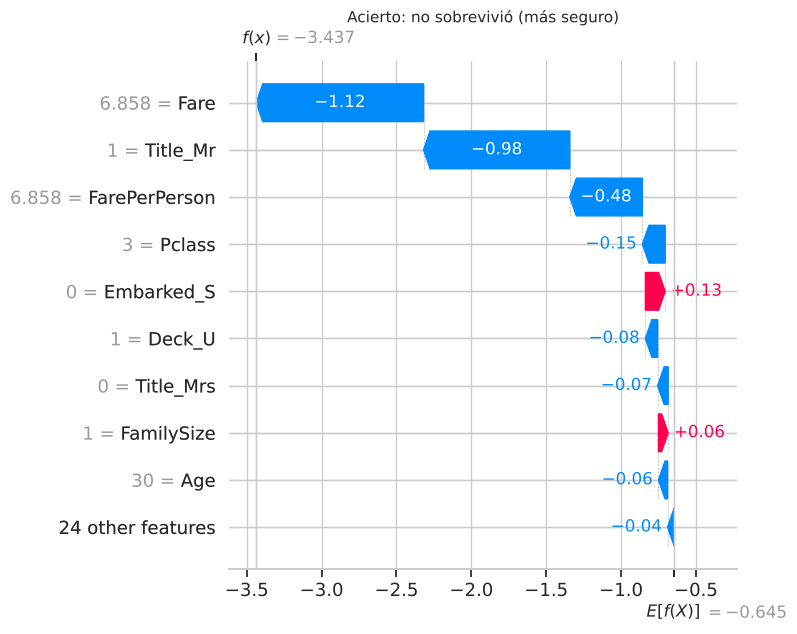

Dudoso (cerca del umbral): Newell, Mr. Arthur Webster | male, 58.0 años, clase 1 | prob = 31.4% | real: no sobrevivió
   principales contribuciones: Age -1.31, Title_Mr -1.07, Deck_D +0.81, Fare +0.70


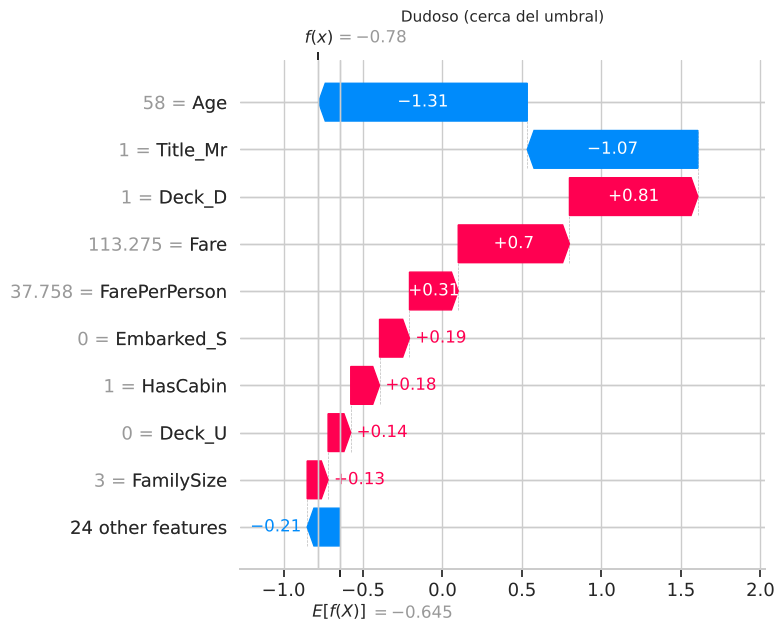

Error: falso positivo más confiado: Minahan, Dr. William Edward | male, 44.0 años, clase 1 | prob = 99.0% | real: no sobrevivió
   principales contribuciones: Title_Mr +1.12, Fare +0.83, FarePerPerson +0.80, HasCabin +0.54


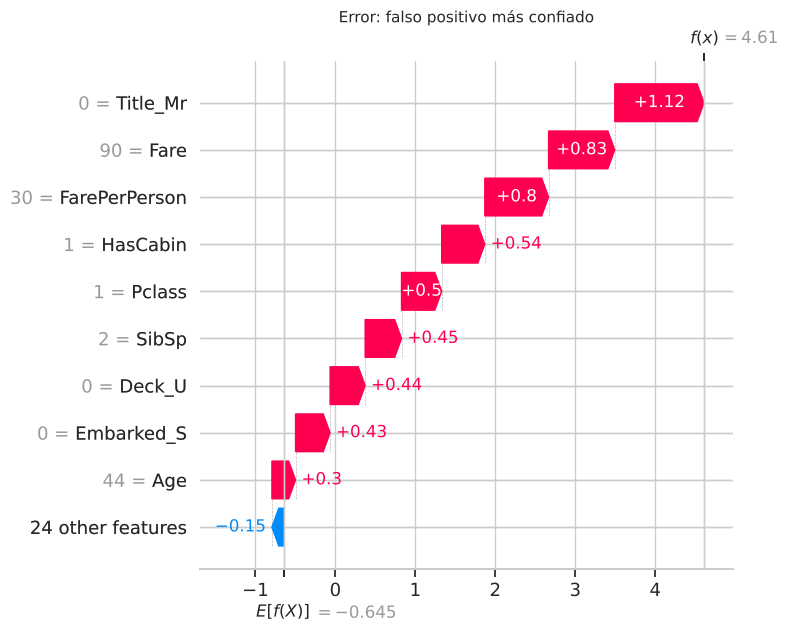

Error: falso negativo más confiado: Tornquist, Mr. William Henry | male, 25.0 años, clase 3 | prob = 3.0% | real: sobrevivió
   principales contribuciones: Fare -1.08, Title_Mr -0.99, FarePerPerson -0.39, Pclass -0.14


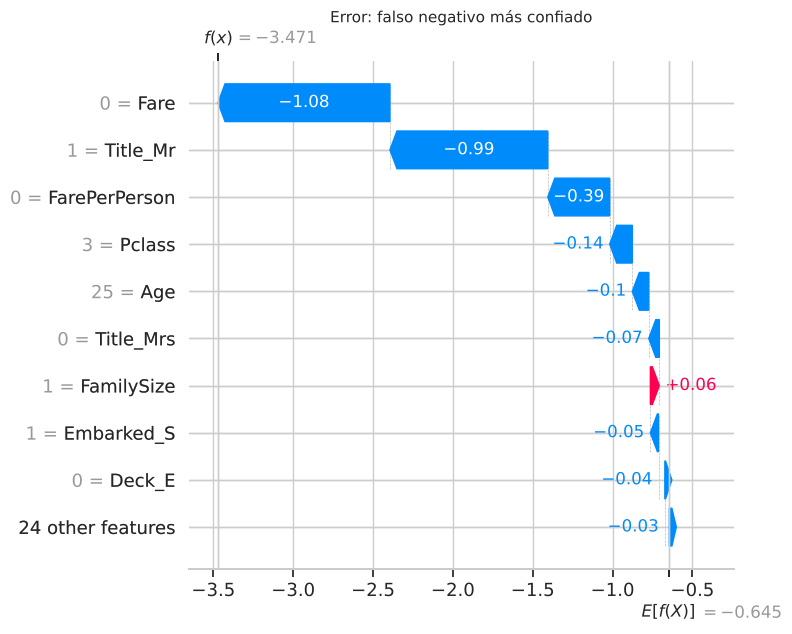

In [13]:
for caso, i in pos.items():
    r = info.iloc[i]
    print(f"{caso}: {r['Name']} | {r['Sex']}, {r['Age'] if pd.notna(r['Age']) else 'edad desconocida'} años, "
          f"clase {r['Pclass']} | prob = {r['Prob']:.1%} | real: {'sobrevivió' if r['Real'] else 'no sobrevivió'}")
    top = pd.Series(sv.values[i], index=nombres).sort_values(key=abs, ascending=False).head(4)
    print("   principales contribuciones:", ", ".join(f"{k} {v:+.2f}" for k, v in top.items()))
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(caso, fontsize=11)
    plt.tight_layout(); plt.show()

**Cómo leer el waterfall:** arranca en `E[f(x)]` (el valor base, −0.645 log-odds ≈ 34 % de probabilidad) y cada barra suma (rojo, hacia sobrevivir) o resta (azul, hacia no sobrevivir) hasta llegar a `f(x)`, la predicción final de ese pasajero.

## 8.8 SHAP vs importancia por permutación

In [14]:
from sklearn.inspection import permutation_importance
f_test = feat.transform(X_test)
perm = permutation_importance(pipe.named_steps["model"], Xm_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
perm_g = pd.Series(perm.importances_mean, index=nombres)
perm_g = perm_g.groupby(perm_g.index.map(grupo)).sum()

comp = pd.DataFrame({"SHAP_%": imp_grupo_pct,
                     "Permutación_%": (perm_g.clip(lower=0) / perm_g.clip(lower=0).sum() * 100).round(1)})
comp["Rank_SHAP"] = comp["SHAP_%"].rank(ascending=False).astype(int)
comp["Rank_Perm"] = comp["Permutación_%"].rank(ascending=False).astype(int)
comp = comp.sort_values("Rank_SHAP")
comp.to_csv("results/importancia_shap.csv")
comp

,SHAP_%,Permutación_%,Rank_SHAP,Rank_Perm
Title,39.8,54.5,1,1
Pclass,11.1,13.4,2,3
FarePerPerson,10.4,13.5,3,2
Age,8.2,5.7,4,5
Embarked,6.3,3.7,5,6
Fare,5.7,0.0,6,13
Deck,5.3,2.0,7,7
FamilySize,4.7,6.1,8,4
Sex,4.2,0.0,9,13
HasCabin,2.1,0.0,10,13


## 8.9 Conclusiones

**1. ¿Qué importa más?** (porcentaje de la importancia SHAP total)

| Característica | % | Interpretación |
|---|---|---|
| **Título** | **39.8 %** | Resume sexo + edad + estado social. Por sí solo pesa casi como todas las demás juntas. |
| Clase | 11.1 % | Nivel socioeconómico y cercanía a los botes |
| Tarifa por persona | 10.4 % | Igual que la clase, pero más fina |
| Edad | 8.2 % | "Niños primero" |
| Puerto, tarifa, cubierta, familia, sexo | 4–6 % c/u | Efectos secundarios |

`Title_Mr` es la variable individual más decisiva: ser **hombre adulto** es lo que más baja la probabilidad de sobrevivir.

**2. Dirección y forma de los efectos (cuantificado):**
- **Edad:** niños de 0–12 años **+0.49** log-odds; adolescentes +0.19; jóvenes ≈ 0; adultos 36–60 −0.30; **mayores de 60 −1.20**. El modelo aprendió "niños primero" y que los mayores tuvieron muy pocas oportunidades.
- **Tamaño de familia:** de 1 a 4 personas el efecto es pequeño y positivo (+0.08 a +0.17), pero las **familias de 5 o más** bajan **−0.97**. Es una relación **no lineal** que un modelo lineal no captaría bien.
- **Clase:** 1.ª y 2.ª suben la probabilidad; 3.ª la baja.

**3. Interacción clase × sexo.** La interacción más fuerte del modelo es `Pclass × Title_Mr`. La clase **pesa mucho más para las mujeres que para los hombres**:

| Clase | Efecto en hombres | Efecto en mujeres |
|---|---|---|
| 1.ª | +0.20 | **+0.66** |
| 2.ª | +0.19 | **+0.59** |
| 3.ª | −0.20 | **−0.73** |

En otras palabras, para un hombre la clase cambiaba poco (casi todos murieron), pero para una mujer la clase era decisiva: las de 1.ª y 2.ª casi siempre se salvaron y las de 3.ª solo la mitad (como se vio en el EDA). Esto explica por qué los **modelos de árboles** (que capturan interacciones) superaron a la Regresión Logística en el cuaderno 6.

**4. Lo que revelan los errores (lo más valioso de SHAP):**
- **Falso positivo — Dr. William Minahan** (hombre, 44, 1.ª clase, prob. 99 %, no sobrevivió). Su mayor contribución fue `Title_Mr` **+1.12**: como su título es "Dr" y no "Mr", el modelo lo trató como si **no fuera hombre adulto**. El grupo de títulos "Rare" mezcla mujeres (Lady, Countess) con hombres (Dr, Col, Rev), y el modelo depende de "no ser Mr" más que de la variable `Sex`. **Mejora posible:** separar "Rare" en títulos raros de hombre y de mujer.
- **Falso negativo — William Tornquist** (hombre, 25, 3.ª clase, prob. 3 %, sí sobrevivió). Su mayor contribución fue `Fare` **−1.08**: pagó **tarifa 0**. Las tarifas en 0 corresponden a boletos especiales (empleados de la naviera), no a pasajeros pobres, y el modelo las interpreta como "muy pobre". **Mejora posible:** marcar `Fare == 0` como valor faltante o como una categoría especial.
- **Dudoso — Arthur Newell** (58, 1.ª clase, 31 %): primera clase y cabina D lo empujan hacia arriba (+0.81, +0.70), pero la edad (−1.31) y ser "Mr" (−1.07) lo bajan. Quedó justo debajo del umbral de 0.32 y el modelo acertó.

**5. SHAP vs permutación.** Ambos métodos coinciden en el top 3 (Título, Clase, Tarifa por persona). Difieren en `Sex`, `Fare` y `HasCabin`: SHAP les da 2–6 % y la permutación 0 %. No es una contradicción: son **variables redundantes** (el sexo ya está en el título; la cabina, en la clase y la tarifa). SHAP reparte el crédito entre ellas, mientras que la permutación no detecta pérdida al desordenar una sola porque la otra la compensa.

**Conclusión general:** el modelo aprendió las mismas reglas que la historia documenta: **"mujeres y niños primero"** y **ventaja de la primera clase**, con una interacción fuerte entre ambas. Sus errores más graves vienen de dos **problemas de los datos** que SHAP permitió encontrar: títulos ambiguos y tarifas en cero.